## Reproduction of the RP research by Argimiro Arratia and Eduardo Sepúlveda

On the applications RQA for Financial Time Series Forecasting.


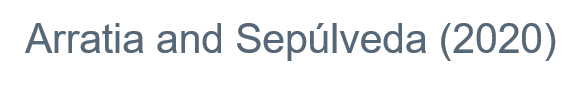

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
DATA_PATH = Path(r"C:\Users\skous\personal knowledge base\RQA Research"
                 r"\RecPlay\data\raw\goyal_welch\Goyal_Welch_2025.xlsx")

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Monthly", engine="openpyxl")

C:\Users\skous\anaconda3\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [4]:
raw["date"] = pd.to_datetime(raw["yyyymm"].astype(str), format="%Y%m")
raw = raw.set_index("date").sort_index() # sort by date

In [5]:
# A check for each month appearing only once
assert raw.index.is_unique, "Duplicate months found"

In [6]:
expected_months = pd.date_range(start=raw.index.min(), end=raw.index.max(), freq="MS")

In [7]:
assert raw.index.equals(expected_months), "Missing months found"

In [8]:
len(raw)

1860

In [9]:
raw.index.min(), raw.index.max()

(Timestamp('1871-01-01 00:00:00'), Timestamp('2025-12-01 00:00:00'))

In [10]:
raw.columns.tolist()

['yyyymm',
 'Index',
 'D12',
 'E12',
 'b/m',
 'tbl',
 'AAA',
 'BAA',
 'lty',
 'ntis',
 'Rfree',
 'infl',
 'ltr',
 'corpr',
 'svar',
 'csp',
 'CRSP_SPvw',
 'CRSP_SPvwx']

In [11]:
columns = ["Index", "D12", "tbl", "Rfree", "CRSP_SPvw"]
display(raw.loc["1990-01":"1990-05", columns])

,Index,D12,tbl,Rfree,CRSP_SPvw
date,,,,,
1990-01-01,329.08,11.142667,0.0764,0.0057,-0.067661
1990-02-01,331.89,11.230333,0.0774,0.0057,0.013381
1990-03-01,339.94,11.318000,0.0790,0.0064,0.026588
1990-04-01,330.80,11.433000,0.0777,0.0069,-0.024504
1990-05-01,361.23,11.548000,0.0774,0.0068,0.097419


In [12]:
display(raw.loc["1990":"2015", columns].isna().sum())
# No nulls

,
Index,0
D12,0
tbl,0
Rfree,0
CRSP_SPvw,0


In [13]:
paper_gross_return = ((raw["Index"] + raw["D12"]) / raw["Index"].shift(1))

premium_candidates = pd.DataFrame({
    "Paper formula, tbl": (np.log(paper_gross_return) - np.log1p(raw["tbl"])),
    "Paper formula, Rfree": (np.log(paper_gross_return) - np.log1p(raw["Rfree"])),
    "CRSP total return, Rfree": (np.log1p(raw["CRSP_SPvw"]) - np.log1p(raw["Rfree"]))
})

In [14]:
study_candidates = premium_candidates.loc["1990":"2015"]
assert study_candidates.notna().all().all()

In [15]:
target_check = pd.DataFrame({
    "Months": study_candidates.count(),
    "Positive months": study_candidates.gt(0).sum(),
    "Positive share": study_candidates.gt(0).mean()
})

display(target_check)

,Months,Positive months,Positive share
"Paper formula, tbl",312,162,0.519231
"Paper formula, Rfree",312,232,0.743590
"CRSP total return, Rfree",312,193,0.618590


In [16]:
# Paper (§2.3): GSPCep = log((P(t) + D12(t)) / P(t-1)) - log(r(t) + 1), r = three-month T-bill (tbl)
premium = np.log((raw["Index"] + raw["D12"]) / raw["Index"].shift(1)) - np.log1p(raw["tbl"])
data = pd.DataFrame({"GSPCep": premium})
data["target"] = premium.gt(0).where(premium.notna()).astype("Int64")

In [17]:
display(data.loc["1990-01":"1990-05"])

,GSPCep,target
date,,
1990-01-01,-0.074166,0
1990-02-01,0.005635,1
1990-03-01,0.020357,1
1990-04-01,-0.031255,0
1990-05-01,0.083884,1


In [18]:
display(data.loc["1990":"2015", "target"].value_counts().sort_index())

,count
target,
0,119
1,193


In [19]:
ep = data["GSPCep"]
features = pd.DataFrame({"ep": ep, "ep_lag1": ep.shift(1), "ep_lag2": ep.shift(2), "ep_sq": ep**2, "ep_sq_lag1": ep.shift(1)**2}).loc["1990":"2015"]

assert np.isfinite(features.to_numpy()).all()
display(features.head())

,ep,ep_lag1,ep_lag2,ep_sq,ep_sq_lag1
date,,,,,
1990-01-01,-0.074166,0.017713,0.012163,0.005501,0.000314
1990-02-01,0.005635,-0.074166,0.017713,0.000032,0.005501
1990-03-01,0.020357,0.005635,-0.074166,0.000414,0.000032
1990-04-01,-0.031255,0.020357,0.005635,0.000977,0.000414
1990-05-01,0.083884,-0.031255,0.020357,0.007037,0.000977


In [20]:
window = 12
values = features.to_numpy(dtype="float32")
dates = features.index[window:]

X = np.stack([values[i-window:i] for i in range(window, len(values))])
y = data.loc[dates, "target"].to_numpy(dtype="int32")

In [21]:
np.testing.assert_allclose(X[:, -1, 0], ep.reindex(dates - pd.DateOffset(months=1)), rtol=1e-6, atol=1e-8)
assert X.shape == (300, 12, 5)

In [22]:
X.shape, y.shape, dates.min(), dates.max(), np.bincount(y)

((300, 12, 5),
 (300,),
 Timestamp('1991-01-01 00:00:00'),
 Timestamp('2015-12-01 00:00:00'),
 array([112, 188]))

In [23]:
cut, gap = int(0.8 * len(X)), window + 2
train_idx, test_idx = np.arange(cut - gap), np.arange(cut, len(X))
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

y_train.mean(), y_test.mean()

(np.float64(0.6194690265486725), np.float64(0.65))

In [24]:
def distances(x):
    return np.sqrt(np.sum((x[:, :, None, :] - x[:, None, :, :])**2, axis=-1))

upper = np.triu_indices(window, k=1)
epsilon = 0.10
d_train, d_test = distances(X_train), distances(X_test)
RP_train = (d_train <= epsilon).astype("float32")[..., None]
RP_test = (d_test <= epsilon).astype("float32")[..., None]

In [25]:
assert np.array_equal(RP_train[..., 0], RP_train[..., 0].transpose(0, 2, 1))

In [26]:
epsilon , RP_train.shape, RP_test.shape, RP_train[:, upper[0], upper[1], 0].mean()

(0.1, (226, 12, 12, 1), (60, 12, 12, 1), np.float32(0.67223114))

In [27]:
for label, rp in [("Train", RP_train), ("Test", RP_test)]:
    rr = rp[:, upper[0], upper[1], 0].mean(axis=1)
    print(label, rp.shape, "mean recurrence:", rr.mean(), "diagonal-only images:", (rr == 0).sum())

Train (226, 12, 12, 1) mean recurrence: 0.67223114 diagonal-only images: 0
Test (60, 12, 12, 1) mean recurrence: 0.7371212 diagonal-only images: 0


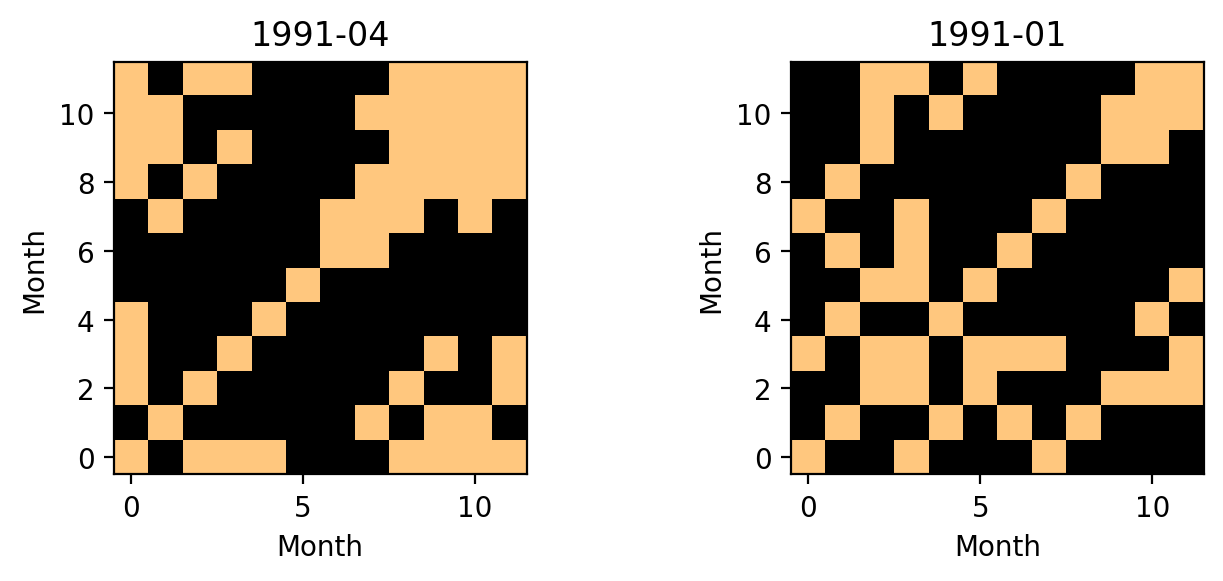

In [28]:
import matplotlib.pyplot as plt

i0 = np.flatnonzero(y_train == 0)[0]
i1 = np.flatnonzero(y_train == 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(RP_train[i0, :, :, 0], cmap="copper", vmin=0, vmax=1, origin="lower")
axes[1].imshow(RP_train[i1, :, :, 0], cmap="copper", vmin=0, vmax=1, origin="lower")
axes[0].set(title=f"{dates[train_idx[i0]]:%Y-%m}", xlabel="Month", ylabel="Month")
axes[1].set(title=f"{dates[train_idx[i1]]:%Y-%m}", xlabel="Month", ylabel="Month")
plt.tight_layout()
plt.show()

In [29]:
import torch
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())

2.14.0+cu130 13.0 True


In [30]:
from torch import nn
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, matthews_corrcoef
from sklearn.model_selection import StratifiedKFold

device = torch.device("cuda")
torch.backends.cudnn.benchmark = False
device

device(type='cuda')

In [31]:
def build_model(name):
    if name == "Conv1D":
        model = nn.Sequential(nn.Conv1d(5, 64, 2), nn.ReLU(), nn.MaxPool1d(2), nn.Flatten(), nn.Linear(64 * 5, 1))
    elif name == "Conv2D + RP":
        model = nn.Sequential(nn.Conv2d(1, 64, 2), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 5 * 5, 1))
    else:
        raise ValueError(name)

    for layer in model.modules():
        if isinstance(layer, (nn.Conv1d, nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

In [32]:
def to_tensor(x, name):
    x = torch.as_tensor(x, dtype=torch.float32, device=device)
    return x.permute(0, 2, 1).contiguous() if name == "Conv1D" else x.permute(0, 3, 1, 2).contiguous()

def score(actual, probability):
    predicted = (probability >= 0.5).astype(int)
    auc = roc_auc_score(actual, probability) if len(np.unique(actual)) == 2 else np.nan
    return {"accuracy": accuracy_score(actual, predicted),
            "loss": log_loss(actual, probability, labels=[0, 1]),
            "auc": auc, "mcc": matthews_corrcoef(actual, predicted)}

def fit_once(name, train_x, train_y, test_x, test_y, seed):
    torch.manual_seed(seed)
    model = build_model(name).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, eps=1e-7)
    criterion = nn.BCEWithLogitsLoss()
    a, b = to_tensor(train_x, name), to_tensor(test_x, name)
    target = torch.as_tensor(train_y, dtype=torch.float32, device=device)
    history = []

    rng = np.random.default_rng(seed)
    for epoch in range(10):
        model.train()
        for i in rng.permutation(len(train_y)):
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(a[i:i+1]).squeeze(1), target[i:i+1])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.inference_mode():
            history.append(criterion(model(a).squeeze(1), target).item())

    with torch.inference_mode():
        probability = torch.sigmoid(model(b)).squeeze(1).cpu().numpy()
    return {"metrics": {"model": name, "seed": seed, **score(test_y, probability)},
            "history": history, "probability": probability}

In [33]:
inputs = {"Conv1D": (X_train, X_test), "Conv2D + RP": (RP_train, RP_test)}
first_runs = {
    name: fit_once(name, a, y_train, b, y_test, seed=0)
    for name, (a, b) in inputs.items()
}
display(pd.DataFrame([run["metrics"] for run in first_runs.values()]))

,model,seed,accuracy,loss,auc,mcc
0,Conv1D,0,0.650000,0.647643,0.520147,0.000000
1,Conv2D + RP,0,0.583333,0.752810,0.496947,-0.128124


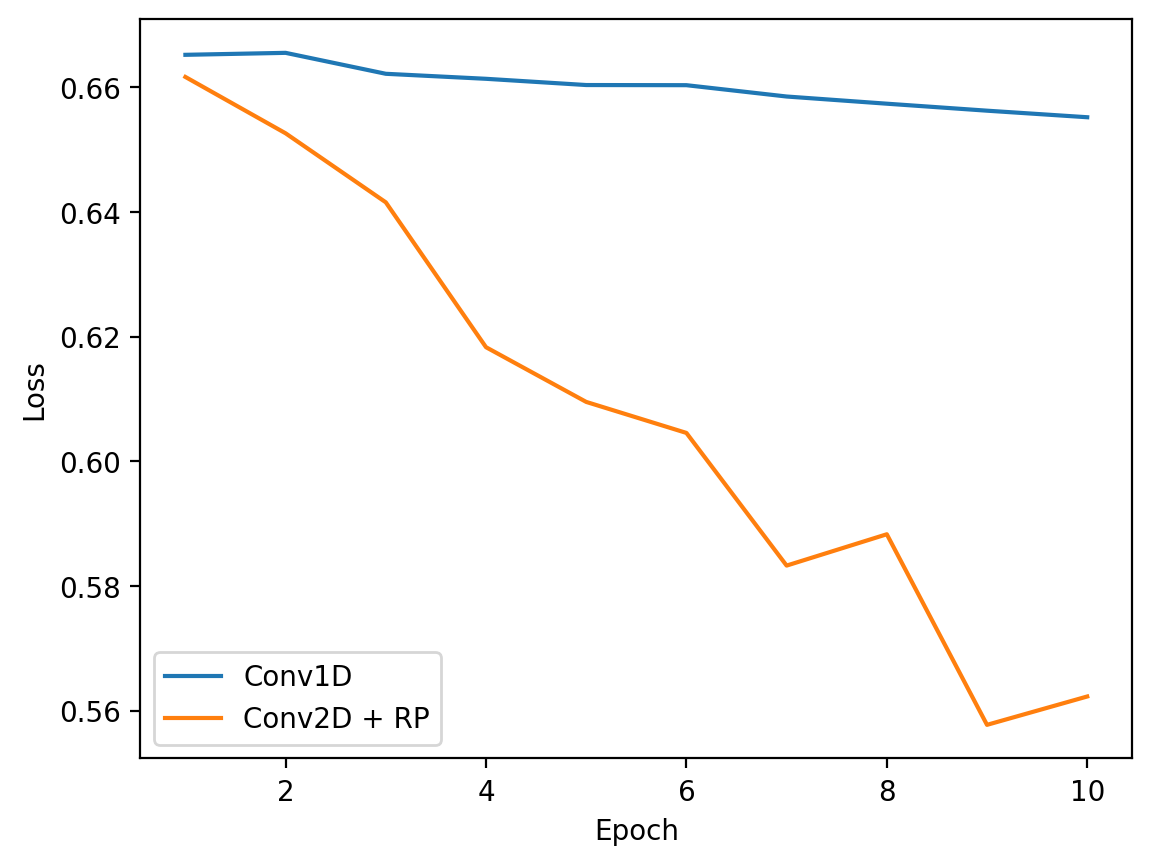

In [34]:
for name, run in first_runs.items():
    plt.plot(range(1, 11), run["history"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [35]:
rows = [run["metrics"] for run in first_runs.values()]
for seed in range(1, 100):
    for name, (a, b) in inputs.items():
        rows.append(fit_once(name, a, y_train, b, y_test, seed)["metrics"])
    if (seed + 1) % 10 == 0:
        print(f"Completed {seed + 1}/100")

results = pd.DataFrame(rows)

Completed 10/100
Completed 20/100
Completed 30/100
Completed 40/100
Completed 50/100
Completed 60/100
Completed 70/100
Completed 80/100
Completed 90/100
Completed 100/100


In [36]:
metrics = ["accuracy", "loss", "auc", "mcc"]
paper = pd.DataFrame({
    "accuracy": [0.52, 0.63], "loss": [5.75, 2.69],
    "auc": [0.65, 0.66], "mcc": [-0.102, -0.0026]
}, index=["Conv1D", "Conv2D + RP"])

ours = results.groupby("model")[metrics].mean().reindex(paper.index)
display(pd.concat({"Paper": paper, "Your run": ours}, axis=1).round(4))
display(results.groupby("model")[metrics].std().round(4))
print(f"Always-positive test accuracy: {y_test.mean():.4f}")

Paper                     Your run                        
            accuracy  loss   auc     mcc accuracy    loss     auc     mcc
Conv1D          0.52  5.75  0.65 -0.1020    0.650  0.6501  0.5083  0.0000
Conv2D + RP     0.63  2.69  0.66 -0.0026    0.575  0.7447  0.4914 -0.0891

,accuracy,loss,auc,mcc
model,,,,
Conv1D,0.0000,0.0024,0.0185,0.0000
Conv2D + RP,0.0167,0.0129,0.0174,0.0661


Always-positive test accuracy: 0.6500


In [37]:
wide = {m: results.pivot(index="seed", columns="model", values=m) for m in metrics}
differences = pd.DataFrame({m: wide[m]["Conv2D + RP"] - wide[m]["Conv1D"] for m in metrics})
display(differences.agg(["mean", "std"]).round(4))
print("Seeds with higher RP accuracy:", differences["accuracy"].gt(0).sum(), "/ 100")

,accuracy,loss,auc,mcc
mean,-0.0750,0.0945,-0.0169,-0.0891
std,0.0167,0.0127,0.0255,0.0661


Seeds with higher RP accuracy: 0 / 100


In [38]:
# Paper: "10-fold cross-validation", justified by Bergmeir et al. (standard K-fold is valid for
# autoregressive features). sklearn/KerasClassifier default for a classifier is StratifiedKFold(10)
# over the whole sample. RPs use the same fixed epsilon as the paper (0.10), not a per-fold quantile;
# each RP depends only on its own window, so building them on all windows leaks nothing.
cv = StratifiedKFold(n_splits=10)
RP_all = (distances(X) <= epsilon).astype("float32")[..., None]
cv_rows = []

for fold, (tr, va) in enumerate(cv.split(X, y), start=1):
    for name, data in [("Conv1D", X), ("Conv2D + RP", RP_all)]:
        cv_rows.append({"fold": fold, **fit_once(name, data[tr], y[tr], data[va], y[va], seed=fold)["metrics"]})
    cv_rows.append({"fold": fold, "model": "Baseline",
                    **score(y[va], np.full(len(va), y[tr].mean()))})
    print(f"Completed fold {fold}/10")

cv_results = pd.DataFrame(cv_rows)
display(cv_results.groupby("model")[metrics].agg(["mean", "std"]).round(4))

Completed fold 1/10
Completed fold 2/10
Completed fold 3/10
Completed fold 4/10
Completed fold 5/10
Completed fold 6/10
Completed fold 7/10
Completed fold 8/10
Completed fold 9/10
Completed fold 10/10


accuracy            loss             auc             mcc        
                mean     std    mean     std    mean     std    mean     std
model                                                                       
Baseline      0.6267  0.0141  0.6608  0.0074  0.5000  0.0000  0.0000  0.0000
Conv1D        0.6200  0.0233  0.6724  0.0139  0.4414  0.1609 -0.0203  0.0643
Conv2D + RP   0.5467  0.0592  0.7652  0.0794  0.4037  0.0863 -0.0974  0.1268

In [39]:
paper_cv = pd.DataFrame({"Paper mean": [0.611, 0.6322], "Paper +/-": [0.0416, 0.0093]}, index=["Conv1D", "Conv2D + RP"])
our_cv = cv_results.groupby("model")["accuracy"].agg(["mean", "std"])
our_cv = our_cv.rename(columns={"mean": "10-fold mean", "std": "SD across folds"})
display(paper_cv.join(our_cv).round(4))

,Paper mean,Paper +/-,10-fold mean,SD across folds
Conv1D,0.6110,0.0416,0.6200,0.0233
Conv2D + RP,0.6322,0.0093,0.5467,0.0592


## Revised CNN pipeline: 1D CNN on windows, 2D CNN on recurrence plots

The cells above are the original attempt. This section reruns the experiment with changes aimed at an honest, stable estimate:

- **More training data.** Windows are built over the long Goyal–Welch history (from `TRAIN_START`, default 1927) with the same features and target as above.
- **Walk-forward evaluation (main result).** Targets in 1990–2015 are predicted in 5-year blocks, each trained only on earlier months. Within the training period, the last 15% (after a `WINDOW`-month gap) is used for early stopping.
- **Train-only preprocessing.** Features are z-scored with training statistics. RP thresholds are fitted on training windows for a fixed recurrence rate (`RP_RATE`), so the images are no longer mostly ones.
- **Multichannel RPs.** One RP per feature plus one multivariate Euclidean RP (6 channels).
- **Small regularized CNNs.** Two conv blocks with BatchNorm, global pooling, dropout, AdamW, mini-batches, early stopping. Output bias starts at the training prior.
- **Seed ensembles.** Probabilities are averaged over `SEEDS`.
- **Baselines and a null.** Training-prior and logistic-regression baselines on the same inputs, plus a label-permutation p-value for AUC.
- **Paper protocol (comparison only).** StratifiedKFold(10) on the original 300 windows from 1991–2015. It is optimistic for overlapping time windows.

Accuracy and MCC use the training-set positive rate as the threshold. AUC does not depend on a threshold.

Uses `raw` from the cells above. Run top to bottom. It does not use `data`, which an earlier cell overwrites in its loop.

In [40]:
import copy
import torch
from torch import nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, matthews_corrcoef, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WINDOW = 12
TRAIN_START = "1927-01-01"   # earliest month allowed in inputs (first valid month is used if later)
TEST_START, TEST_END = "1990-01-01", "2015-12-01"
REFIT_YEARS = 5              # walk-forward refit frequency
RP_RATE = 0.15               # target recurrence rate per RP channel, fitted on training windows
VAL_SHARE = 0.15             # final share of training windows used for early stopping
SEEDS = range(10)            # ensemble size
MAX_EPOCHS, PATIENCE, BATCH = 200, 20, 32
LR, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-3, 0.3
CNN_MODELS = ("Conv1D", "Conv2D + RP")
PAPER = pd.DataFrame({"accuracy": [0.52, 0.63], "auc": [0.65, 0.66], "mcc": [-0.102, -0.0026]},
                     index=list(CNN_MODELS))
print("Device:", DEVICE)

Device: cuda


### Full-history windows

Same features and target as above. Each window covers months *t−12 … t−1* and predicts the sign of month *t*'s premium. Inputs start after the last month with a missing value, so the monthly grid has no gaps.

In [41]:
premium_full = np.log((raw["Index"] + raw["D12"]) / raw["Index"].shift(1)) - np.log1p(raw["tbl"])  # paper formula, as above
feat = pd.DataFrame({
    "ep": premium_full, "ep_lag1": premium_full.shift(1), "ep_lag2": premium_full.shift(2),
    "ep_sq": premium_full ** 2, "ep_sq_lag1": premium_full.shift(1) ** 2,
}).loc[TRAIN_START:TEST_END]
bad = feat.index[feat.isna().any(axis=1)]
if len(bad):
    feat = feat.loc[feat.index > bad.max()]
assert len(feat.asfreq("MS")) == len(feat), "gap in monthly features"
assert np.isfinite(feat.to_numpy()).all()

vals = feat.to_numpy("float32")
win_dates = feat.index[WINDOW:]
X_all = np.stack([vals[i - WINDOW:i] for i in range(WINDOW, len(vals))])
y_all = premium_full.loc[win_dates].gt(0).to_numpy("int64")
np.testing.assert_allclose(X_all[:, -1, 0], premium_full.reindex(win_dates - pd.DateOffset(months=1)), rtol=1e-6, atol=1e-8)

test_mask = (win_dates >= TEST_START) & (win_dates <= TEST_END)
print(f"Inputs from {feat.index[0]:%Y-%m}; {len(X_all)} windows, {test_mask.sum()} test targets "
      f"({win_dates[test_mask][0]:%Y-%m} to {win_dates[test_mask][-1]:%Y-%m}); positive share {y_all.mean():.3f}")

Inputs from 1927-01; 1056 windows, 312 test targets (1990-01 to 2015-12); positive share 0.592


### Preprocessing, models, training

In [42]:
def rp_distances(Z):
    """(n, W, C) -> (n, C + 1, W, W): per-feature |x_i - x_j| plus multivariate Euclidean distance."""
    diff = Z[:, :, None, :] - Z[:, None, :, :]
    per_feature = np.abs(diff).transpose(0, 3, 1, 2)
    euclid = np.sqrt((diff ** 2).sum(-1))[:, None]
    return np.concatenate([per_feature, euclid], axis=1)


def prepare_inputs(fit_idx):
    """Standardize and threshold using only the windows used to fit the models."""
    flat = X_all[fit_idx].reshape(-1, X_all.shape[-1])
    mu, sd = flat.mean(0), flat.std(0)
    sd[sd == 0] = 1.0
    Z = ((X_all - mu) / sd).astype("float32")
    D = rp_distances(Z)
    iu = np.triu_indices(WINDOW, k=1)
    upper = D[fit_idx][:, :, iu[0], iu[1]].transpose(1, 0, 2).reshape(D.shape[1], -1)
    eps = np.quantile(upper, RP_RATE, axis=1)
    return {
        "Conv1D": np.ascontiguousarray(Z.transpose(0, 2, 1)),                # (n, C, W)
        "Conv2D + RP": (D <= eps[None, :, None, None]).astype("float32"),   # (n, C + 1, W, W)
        "Flat": Z.reshape(len(Z), -1),
    }


def conv_block(dim, c_in, c_out):
    conv, norm = (nn.Conv1d, nn.BatchNorm1d) if dim == 1 else (nn.Conv2d, nn.BatchNorm2d)
    return nn.Sequential(conv(c_in, c_out, 3, padding=1), norm(c_out), nn.ReLU())


def build_cnn(kind, channels):
    if kind == "Conv1D":
        body = nn.Sequential(conv_block(1, channels, 16), conv_block(1, 16, 32), nn.AdaptiveAvgPool1d(1))
    elif kind == "Conv2D + RP":
        body = nn.Sequential(conv_block(2, channels, 16), nn.MaxPool2d(2), conv_block(2, 16, 32), nn.AdaptiveAvgPool2d(1))
    else:
        raise ValueError(kind)
    return nn.Sequential(body, nn.Flatten(), nn.Dropout(DROPOUT), nn.Linear(32, 1))


def train_cnn(kind, x_fit, y_fit, x_val, y_val, seed):
    torch.manual_seed(seed)
    model = build_cnn(kind, x_fit.shape[1]).to(DEVICE)
    prior = float(np.clip(y_fit.mean(), 1e-3, 1 - 1e-3))
    nn.init.constant_(model[-1].bias, np.log(prior / (1 - prior)))
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss()
    xf = torch.as_tensor(x_fit, device=DEVICE)
    yf = torch.as_tensor(y_fit, dtype=torch.float32, device=DEVICE)
    xv = torch.as_tensor(x_val, device=DEVICE)
    yv = torch.as_tensor(y_val, dtype=torch.float32, device=DEVICE)
    generator = torch.Generator().manual_seed(seed)

    best_loss, best_state, wait = np.inf, None, 0
    for _ in range(MAX_EPOCHS):
        model.train()
        for batch in torch.randperm(len(yf), generator=generator).split(BATCH):
            if len(batch) < 2:  # BatchNorm needs more than one sample
                continue
            batch = batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            criterion(model(xf[batch]).squeeze(1), yf[batch]).backward()
            optimizer.step()
        model.eval()
        with torch.inference_mode():
            val_loss = criterion(model(xv).squeeze(1), yv).item()
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    if best_state is None:
        raise RuntimeError(f"{kind}: validation loss never became finite")
    model.load_state_dict(best_state)
    return model.eval()


def predict(model, x):
    with torch.inference_mode():
        return torch.sigmoid(model(torch.as_tensor(x, device=DEVICE)).squeeze(1)).cpu().numpy()


def ensemble_probability(kind, inputs, fit, val, test):
    x = inputs[kind]
    return np.mean([predict(train_cnn(kind, x[fit], y_all[fit], x[val], y_all[val], seed), x[test])
                    for seed in SEEDS], axis=0)


def all_probabilities(inputs, fit, val, test):
    train = np.concatenate([fit, val])
    logistic = LogisticRegression(C=0.1, max_iter=5000).fit(inputs["Flat"][train], y_all[train])
    probs = {"Prior": np.full(len(test), y_all[train].mean()),
             "Logistic": logistic.predict_proba(inputs["Flat"][test])[:, 1]}
    for kind in CNN_MODELS:
        probs[kind] = ensemble_probability(kind, inputs, fit, val, test)
    return probs


def evaluate(actual, probability, threshold):
    predicted = (probability >= threshold).astype(int)
    return {"auc": roc_auc_score(actual, probability),
            "brier": brier_score_loss(actual, probability),
            "log_loss": log_loss(actual, np.clip(probability, 1e-6, 1 - 1e-6), labels=[0, 1]),
            "accuracy": accuracy_score(actual, predicted),
            "mcc": matthews_corrcoef(actual, predicted)}

### Walk-forward evaluation (main result)

**Computationally heavy.** Each block trains `len(SEEDS)` × 2 CNNs. With the defaults that is 6 blocks × 20 = 120 fits.

In [43]:
block_starts = pd.date_range(TEST_START, TEST_END, freq=f"{REFIT_YEARS}YS")
records = []
for b, start in enumerate(block_starts):
    end = block_starts[b + 1] if b + 1 < len(block_starts) else pd.Timestamp(TEST_END) + pd.offsets.MonthBegin(1)
    test = np.flatnonzero((win_dates >= start) & (win_dates < end))
    train = np.flatnonzero(win_dates < start)
    n_val = int(round(VAL_SHARE * len(train)))
    fit, val = train[: len(train) - n_val - WINDOW], train[-n_val:]  # WINDOW-month gap before validation

    probs = all_probabilities(prepare_inputs(fit), fit, val, test)
    threshold = y_all[train].mean()
    for j, row in enumerate(test):
        records.append({"date": win_dates[row], "y": y_all[row], "threshold": threshold,
                        **{m: p[j] for m, p in probs.items()}})
    print(f"Block {start:%Y}-{win_dates[test[-1]]:%Y}: train {len(fit)} / val {len(val)} / test {len(test)}")

wf = pd.DataFrame(records).set_index("date").sort_index()

Block 1990-1994: train 620 / val 112 / test 60
Block 1995-1999: train 671 / val 121 / test 60
Block 2000-2004: train 722 / val 130 / test 60
Block 2005-2009: train 773 / val 139 / test 60
Block 2010-2014: train 824 / val 148 / test 60
Block 2015-2015: train 875 / val 157 / test 12


In [44]:
models = ["Prior", "Logistic", *CNN_MODELS]
y_wf, thr_wf = wf["y"].to_numpy(), wf["threshold"].to_numpy()
wf_summary = pd.DataFrame({m: evaluate(y_wf, wf[m].to_numpy(), thr_wf) for m in models}).T

# Label-permutation null for AUC (monthly premium signs show little serial dependence).
rng = np.random.default_rng(0)
for m in models[1:]:
    p = wf[m].to_numpy()
    observed = roc_auc_score(y_wf, p)
    null = np.array([roc_auc_score(rng.permutation(y_wf), p) for _ in range(2000)])
    wf_summary.loc[m, "auc_perm_p"] = (1 + (null >= observed).sum()) / (1 + len(null))

print(f"Walk-forward test: {len(wf)} months, positive share {y_wf.mean():.3f}")
display(wf_summary.round(4))
display(pd.concat({"Paper": PAPER, "Walk-forward": wf_summary.loc[list(CNN_MODELS), PAPER.columns]}, axis=1).round(4))

Walk-forward test: 312 months, positive share 0.619


,auc,brier,log_loss,accuracy,mcc,auc_perm_p
Prior,0.4407,0.2373,0.6675,0.4904,0.0180,NaN
Logistic,0.5215,0.2381,0.6689,0.5449,0.0478,0.2764
Conv1D,0.5457,0.2363,0.6655,0.5577,0.0897,0.0795
Conv2D + RP,0.4787,0.2388,0.6708,0.5833,0.0524,0.7506


Paper               Walk-forward                
            accuracy   auc     mcc     accuracy     auc     mcc
Conv1D          0.52  0.65 -0.1020       0.5577  0.5457  0.0897
Conv2D + RP     0.63  0.66 -0.0026       0.5833  0.4787  0.0524

### Paper protocol: StratifiedKFold(10) on the original 300 windows (comparison only)

The same models, preprocessing, and ensembles, using the paper's evaluation. Within each fold, 15% of the training windows (stratified) go to early stopping. Overlapping windows make this optimistic compared with walk-forward.

In [45]:
paper_idx = np.flatnonzero((win_dates >= "1991-01-01") & (win_dates <= TEST_END))
assert len(paper_idx) == 300, len(paper_idx)

fold_rows = []
for fold, (tr_pos, te_pos) in enumerate(StratifiedKFold(n_splits=10).split(paper_idx, y_all[paper_idx]), start=1):
    train, test = paper_idx[tr_pos], paper_idx[te_pos]
    fit, val = train_test_split(train, test_size=VAL_SHARE, stratify=y_all[train], random_state=fold)
    probs = all_probabilities(prepare_inputs(fit), fit, val, test)
    for m, p in probs.items():
        fold_rows.append({"fold": fold, "model": m, **evaluate(y_all[test], p, y_all[train].mean())})
    print(f"Completed fold {fold}/10")

kfold = pd.DataFrame(fold_rows)
kfold_summary = kfold.groupby("model")[["auc", "brier", "accuracy", "mcc"]].agg(["mean", "std"]).reindex(models)
display(kfold_summary.round(4))
display(pd.concat({"Paper": PAPER,
                   "10-fold mean": kfold.groupby("model")[list(PAPER.columns)].mean().reindex(list(CNN_MODELS))},
                  axis=1).round(4))

Completed fold 1/10
Completed fold 2/10
Completed fold 3/10
Completed fold 4/10
Completed fold 5/10
Completed fold 6/10
Completed fold 7/10
Completed fold 8/10
Completed fold 9/10
Completed fold 10/10


auc           brier         accuracy             mcc        
               mean     std    mean     std     mean     std    mean     std
model                                                                       
Prior        0.5000  0.0000  0.2340  0.0036   0.6267  0.0141  0.0000  0.0000
Logistic     0.4316  0.1087  0.2670  0.0306   0.4533  0.0958 -0.0819  0.1947
Conv1D       0.2734  0.1731  0.2416  0.0108   0.4533  0.1372 -0.1093  0.2388
Conv2D + RP  0.3346  0.1732  0.2581  0.0397   0.3933  0.1647 -0.2092  0.3094

Paper               10-fold mean                
            accuracy   auc     mcc     accuracy     auc     mcc
Conv1D          0.52  0.65 -0.1020       0.4533  0.2734 -0.1093
Conv2D + RP     0.63  0.66 -0.0026       0.3933  0.3346 -0.2092